# Data Science Lifecycle - Assignment 1
## Beginner-friendly analysis of the automobile dataset

This notebook is a simple version of the assignment. It shows how to:
- load the dataset
- check missing values
- clean the data
- describe the data
- group the data
- study the relationship with price


## 1. Load the raw dataset
We begin with the original automobileEDA.csv file. We will clean this data before saving it.


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('automobileEDA.csv')
print('Number of rows:', len(df))
print('Number of columns:', len(df.columns))
print(df.head())


Number of rows: 201
Number of columns: 29
   symboling  normalized-losses         make aspiration num-of-doors  \
0          3                122  alfa-romero        std          two   
1          3                122  alfa-romero        std          two   
2          1                122  alfa-romero        std          two   
3          2                164         audi        std         four   
4          2                164         audi        std         four   

    body-style drive-wheels engine-location  wheel-base    length  ...  \
0  convertible          rwd           front        88.6  0.811148  ...   
1  convertible          rwd           front        88.6  0.811148  ...   
2    hatchback          rwd           front        94.5  0.822681  ...   
3        sedan          fwd           front        99.8  0.848630  ...   
4        sedan          4wd           front        99.4  0.848630  ...   

   compression-ratio  horsepower  peak-rpm city-mpg highway-mpg    price  \
0   

# Check missing values and duplicates


In [26]:
# Check missing values
missing = df.isnull().sum()
print('Missing values in each column:')
print(missing[missing > 0])

# Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print('Duplicate rows found before cleaning:', duplicate_rows)

# Fill numeric missing values with the median
for column in df.select_dtypes(include='number').columns:
    if df[column].isnull().any():
        median_value = df[column].median()
        df[column] = df[column].fillna(median_value)
        print(f'Filled {column} with median = {median_value}')

# Fill categorical missing values with the most common value (mode)
for column in df.select_dtypes(include=['object', 'string']).columns:
    if df[column].isnull().any():
        mode_value = df[column].mode()[0]
        df[column] = df[column].fillna(mode_value)
        print(f'Filled {column} with mode = {mode_value}')

# Remove duplicate rows after filling missing values
df = df.drop_duplicates()
print('Rows after removing duplicates:', len(df))
print('Missing values left:', int(df.isnull().sum().sum()))


Missing values in each column:
stroke               4
horsepower-binned    1
dtype: int64
Duplicate rows found before cleaning: 0
Filled stroke with median = 3.29
Filled horsepower-binned with mode = Low
Rows after removing duplicates: 201
Missing values left: 0


# Handling outliers

In [27]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_count = ((df['price'] < lower_limit) | (df['price'] > upper_limit)).sum()
print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')
print(f'Lower limit: {lower_limit}')
print(f'Upper limit: {upper_limit}')
print(f'Number of outliers in price: {outlier_count}')

# Cap the values to the normal range
df['price'] = df['price'].clip(lower=lower_limit, upper=upper_limit)
print('Outliers were capped to the IQR limits.')

# Capping can make two rows identical, so remove any duplicates again
df = df.drop_duplicates()
print('Rows after final duplicate check:', len(df))


Q1: 7775.0
Q3: 16500.0
IQR: 8725.0
Lower limit: -5312.5
Upper limit: 29587.5
Number of outliers in price: 14
Outliers were capped to the IQR limits.
Rows after final duplicate check: 200


Saving the cleaned dataset

In [28]:
df.to_csv('Namubiru_Data.csv', index=False)
print('Cleaned dataset saved as Namubiru_Data.csv')
print('Rows:', len(df))
print('Columns:', len(df.columns))


Cleaned dataset saved as Namubiru_Data.csv
Rows: 200
Columns: 29


# Loading the saved cleaned data for the analysis below

In [29]:

df = pd.read_csv('Namubiru_Data.csv')
print('Cleaned dataset loaded for analysis.')
print('Rows:', len(df))


Cleaned dataset loaded for analysis.
Rows: 200


## 2. Descriptive statistics and distributions
We summarize all continuous variables, count the categories, and use graphs to study how the variables are distributed.


In [30]:
# Separate continuous and categorical columns
numeric_columns = df.select_dtypes(include='number').columns.tolist()
categorical_code_columns = ['symboling', 'diesel', 'gas']
continuous_columns = [column for column in numeric_columns if column not in categorical_code_columns]
categorical_columns = df.select_dtypes(include=['object', 'string']).columns.tolist()
categorical_columns = categorical_columns + categorical_code_columns

# Summary statistics for continuous variables
print('Summary statistics for continuous variables:')
print(df[continuous_columns].describe().T.round(2))

# Frequency counts for categorical variables
for column in categorical_columns:
    print(f'\nFrequency counts for {column}:')
    print(df[column].value_counts())


Summary statistics for continuous variables:
                   count      mean      std      min      25%       50%  \
normalized-losses  200.0    122.00    32.08    65.00   100.25    122.00   
wheel-base         200.0     98.84     6.05    86.60    94.50     97.00   
length             200.0      0.84     0.06     0.68     0.80      0.83   
width              200.0      0.92     0.03     0.84     0.89      0.91   
height             200.0     53.78     2.45    47.80    52.00     54.10   
curb-weight        200.0   2554.66   518.40  1488.00  2163.00   2414.00   
engine-size        200.0    126.54    41.38    61.00    97.75    119.50   
bore               200.0      3.33     0.27     2.54     3.15      3.31   
stroke             200.0      3.26     0.32     2.07     3.12      3.29   
compression-ratio  200.0     10.17     4.01     7.00     8.57      9.00   
horsepower         200.0    102.89    36.73    48.00    70.00     95.00   
peak-rpm           200.0   5113.75   476.08  4150.00  4

## Graphs of variable distributions
The histograms show the continuous variables. The bar charts show the categorical variables. For categories with many values, the chart displays the 10 most common.


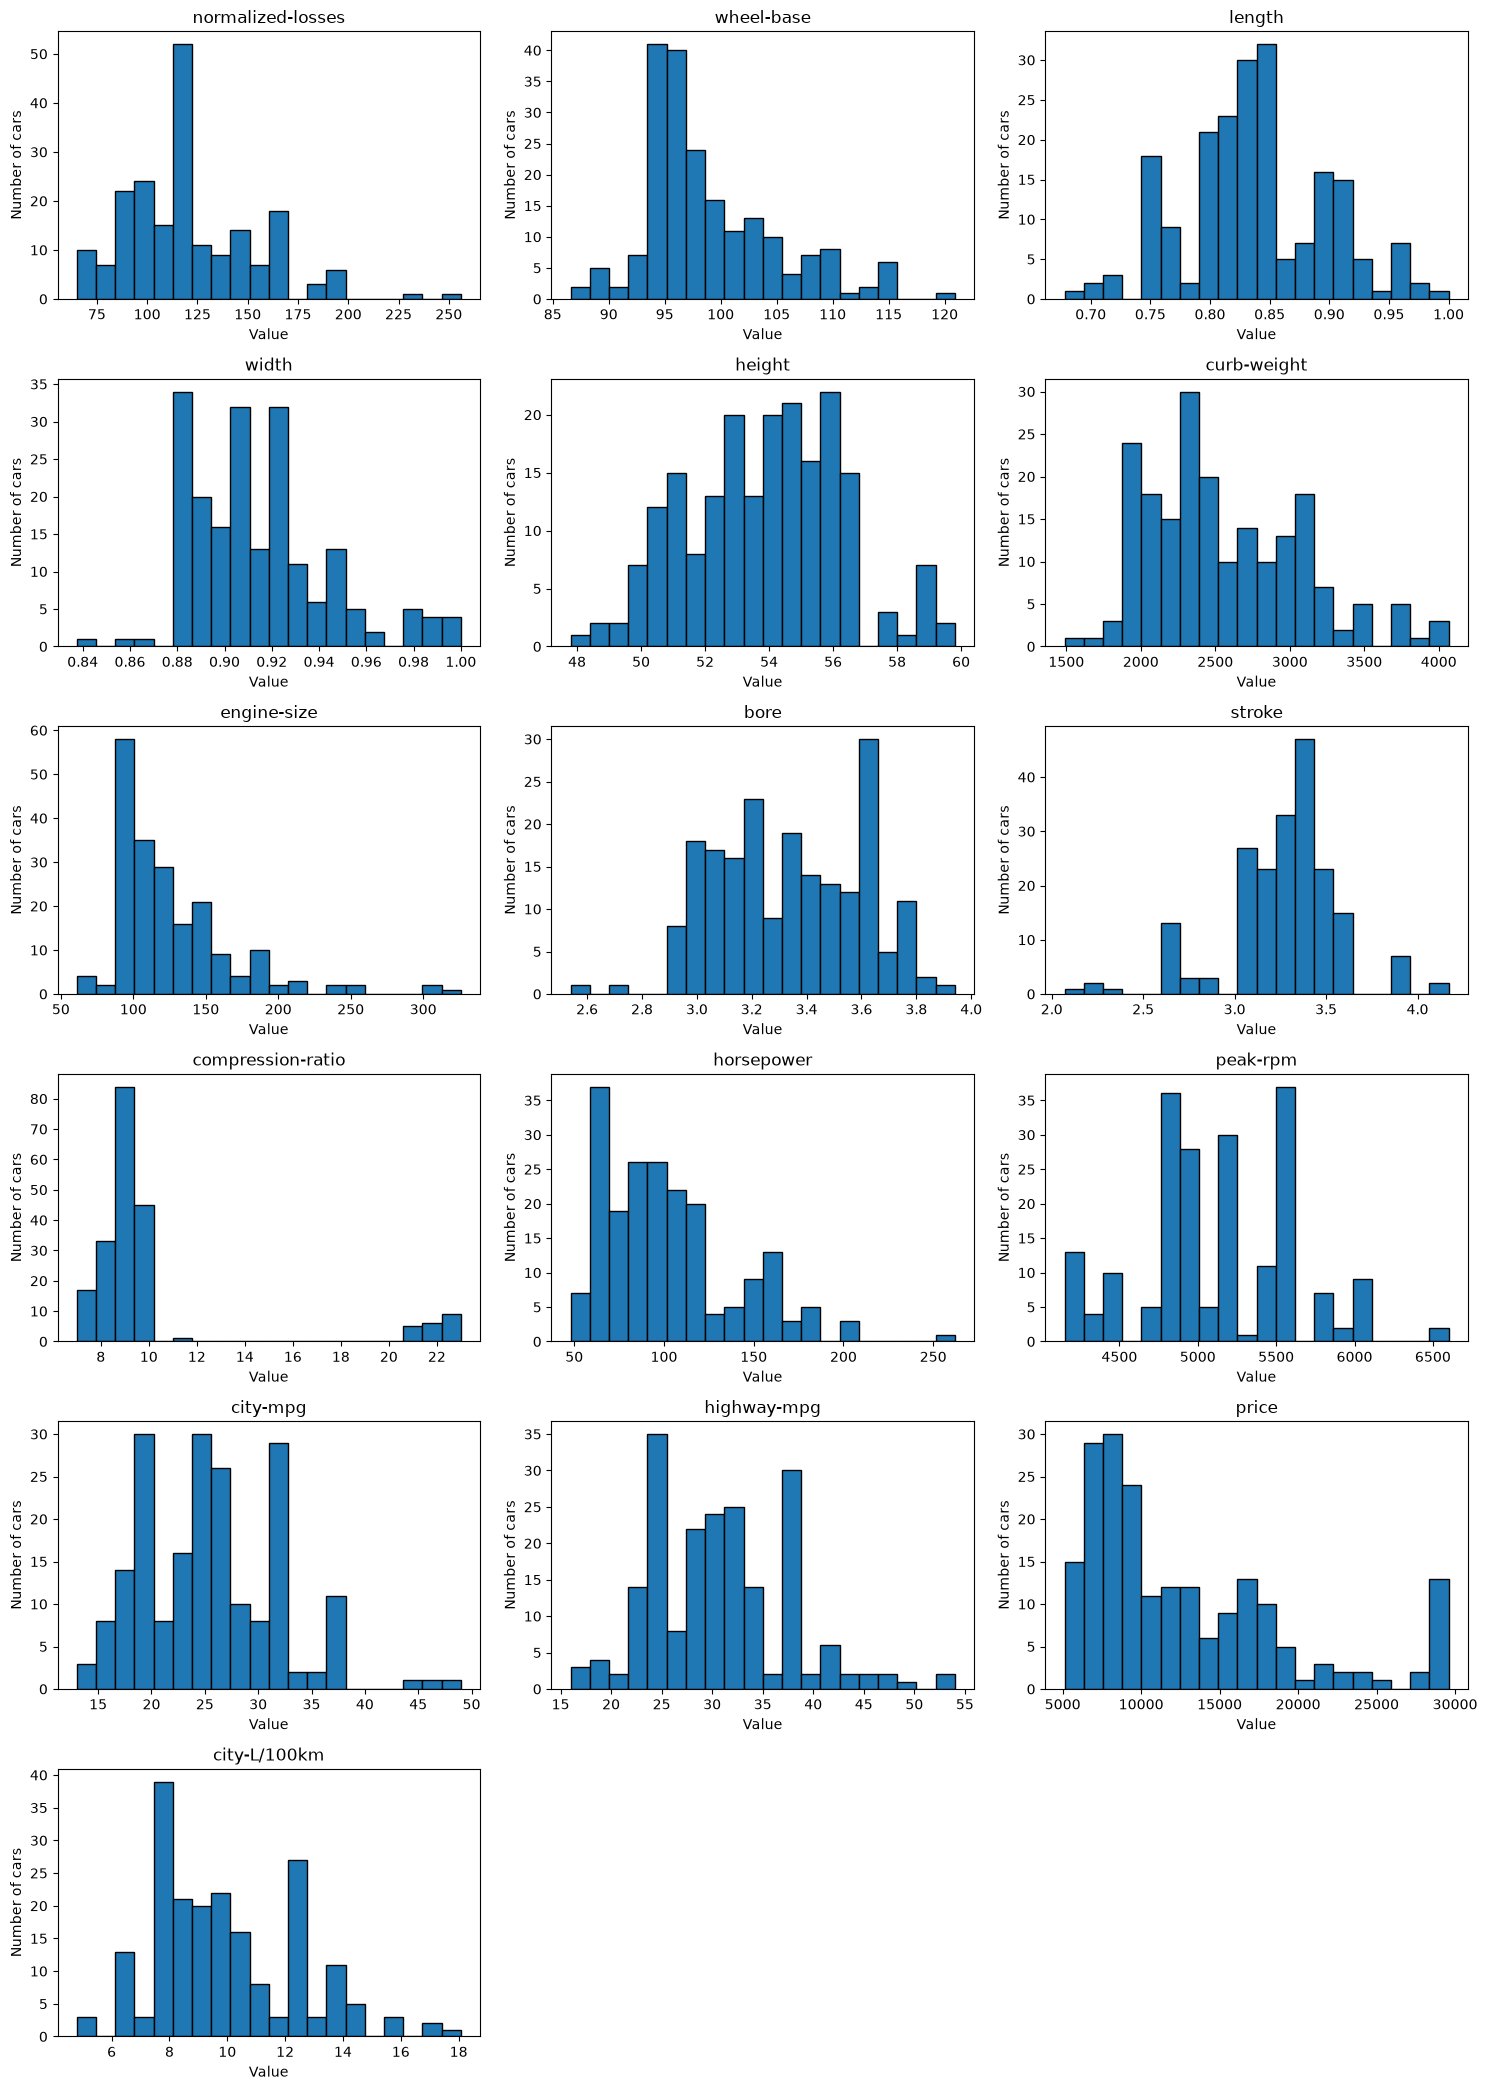

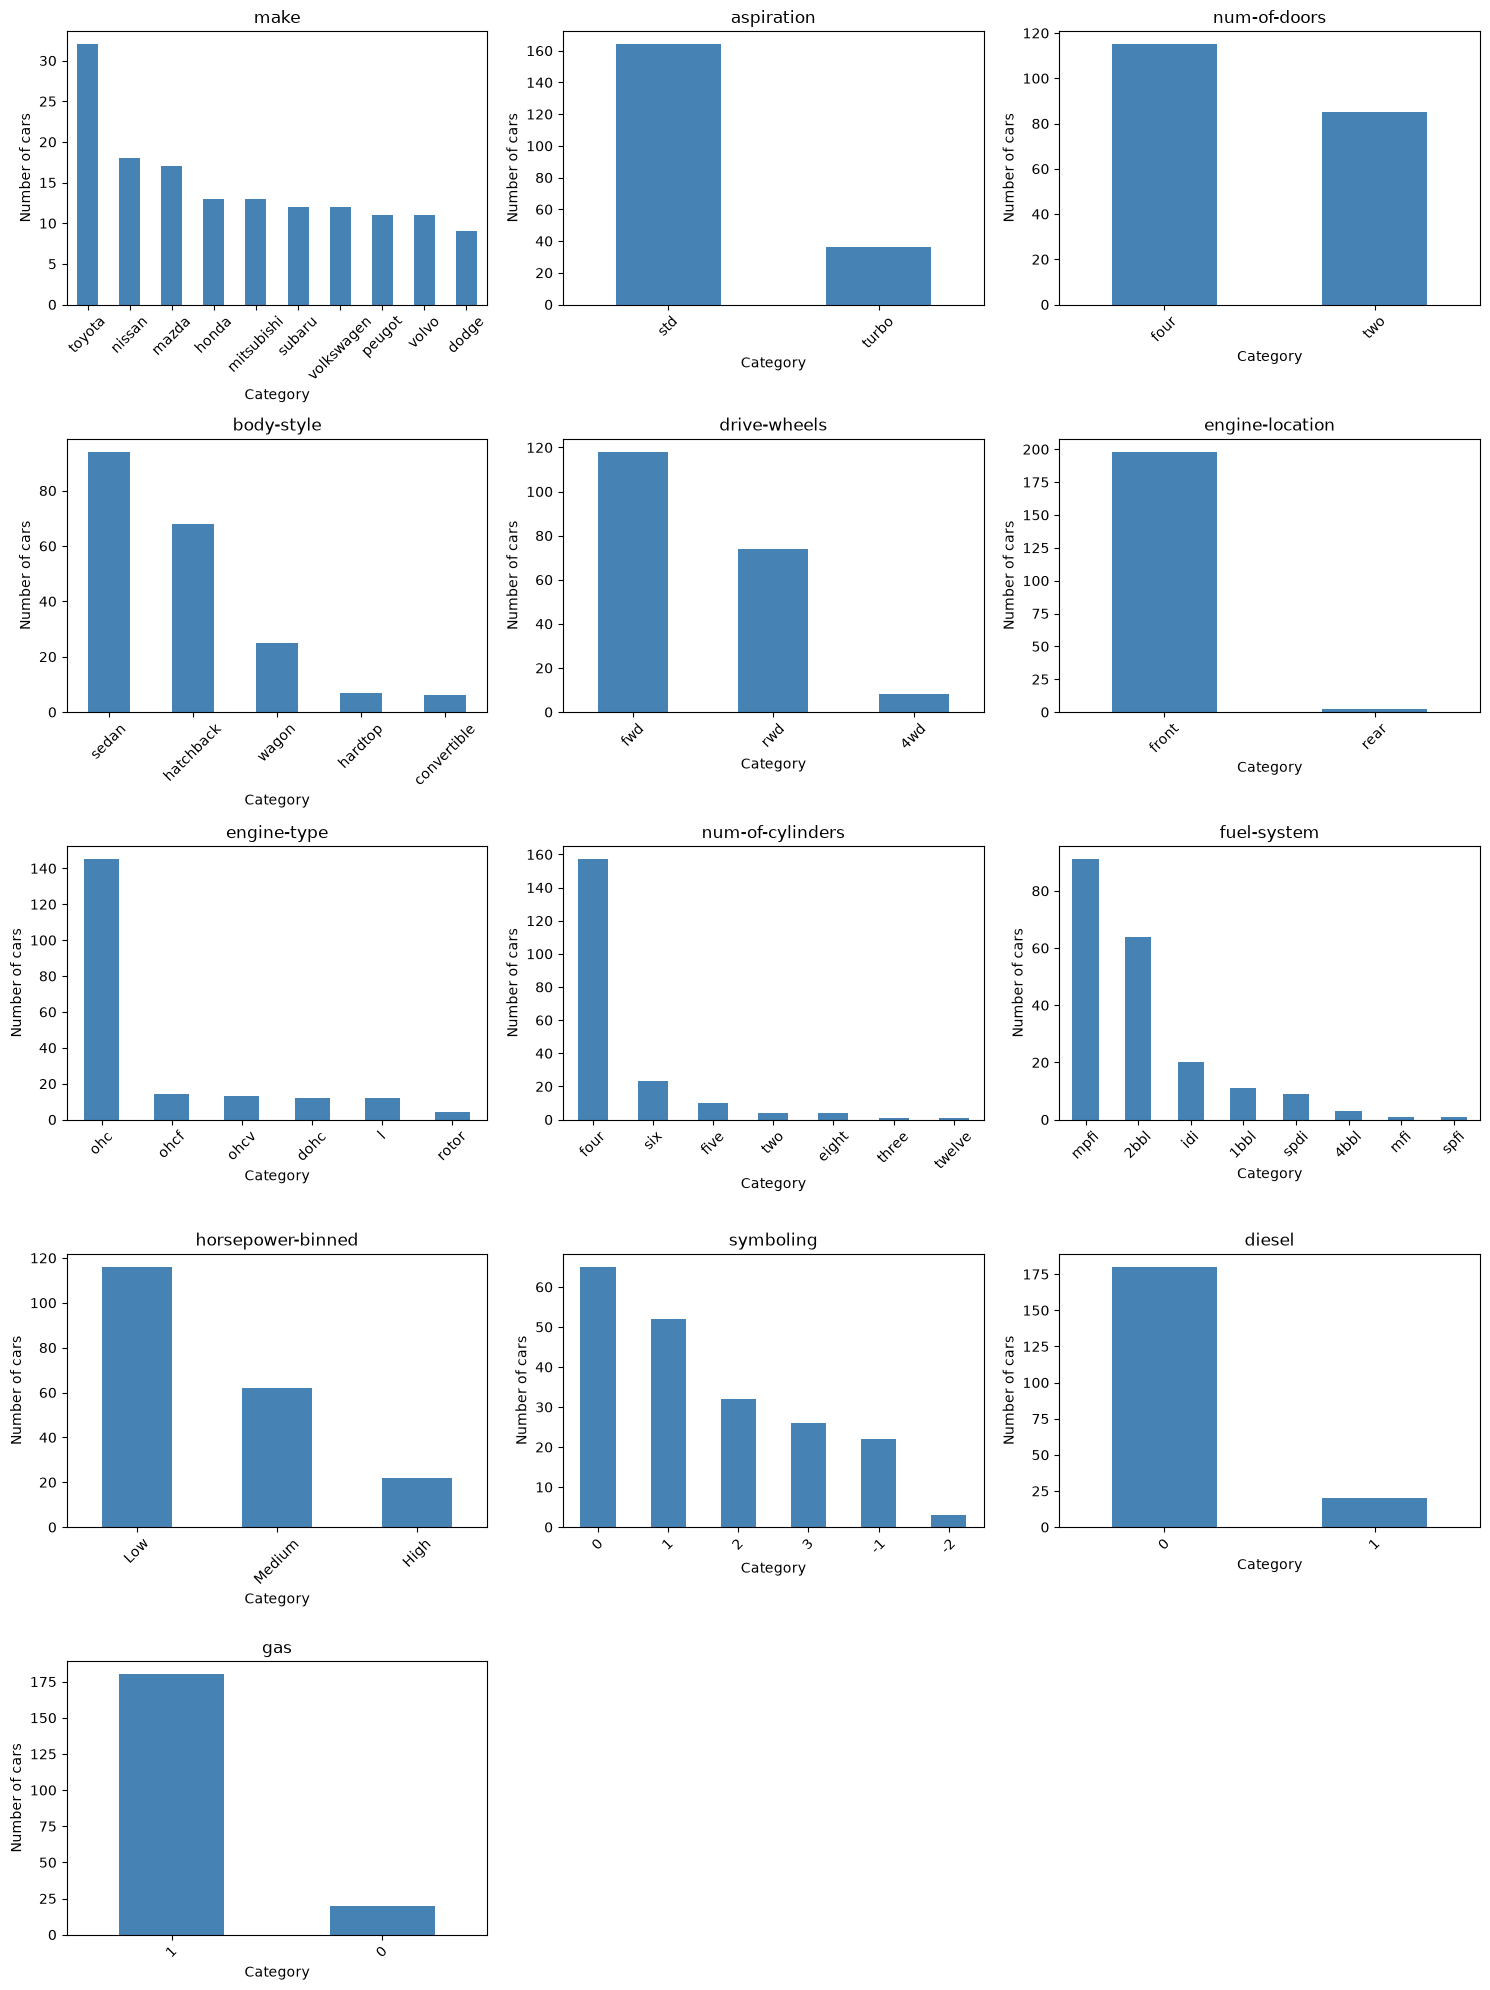

In [31]:
# Draw a histogram for each continuous variable
number_of_columns = 3
number_of_rows = (len(continuous_columns) + number_of_columns - 1) // number_of_columns
fig, axes = plt.subplots(number_of_rows, number_of_columns, figsize=(15, number_of_rows * 3.5))
axes = axes.flatten()

for i, column in enumerate(continuous_columns):
    axes[i].hist(df[column], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Number of cars')

for i in range(len(continuous_columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Draw bar charts for categorical variables. For columns with many groups, show the 10 most common.
number_of_rows = (len(categorical_columns) + number_of_columns - 1) // number_of_columns
fig, axes = plt.subplots(number_of_rows, number_of_columns, figsize=(15, number_of_rows * 4))
axes = axes.flatten()

for i, column in enumerate(categorical_columns):
    counts = df[column].value_counts().head(10)
    counts.plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].set_title(column)
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Number of cars')
    axes[i].tick_params(axis='x', rotation=45)

for i in range(len(categorical_columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


### Patterns observed
The cleaned dataset contains 200 cars. Price is right-skewed: its mean ($12,678.66) is higher than its median ($10,270), which means a smaller number of more expensive cars raise the average. The price values were capped during outlier handling, so the maximum is $29,587.50.

The continuous-variable summaries and histograms show that cars differ in size, weight, engine performance, and fuel economy. The categorical frequency counts show that sedans are the most common body style (94 cars), front-wheel drive is the most common drive type (118 cars), four-cylinder engines are most common (157 cars), and Toyota is the most common make (32 cars). The categorical charts show the 10 most frequent values when a variable has many categories.


# 3. Group the data by body-style and drive-wheels
This helps us see which groups are more expensive.


Average price by body-style:
body-style
convertible    19739.000000
hardtop        17841.000000
sedan          13893.675532
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64


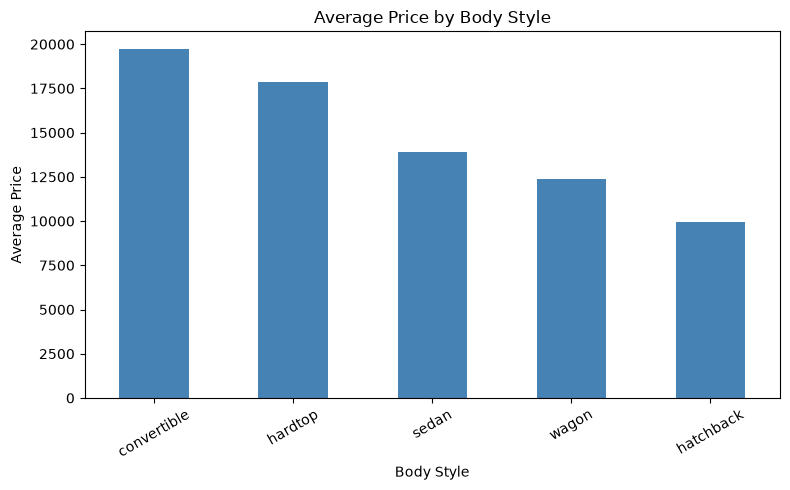

Average price by drive-wheels:
drive-wheels
rwd    18417.831081
4wd    10241.000000
fwd     9244.779661
Name: price, dtype: float64


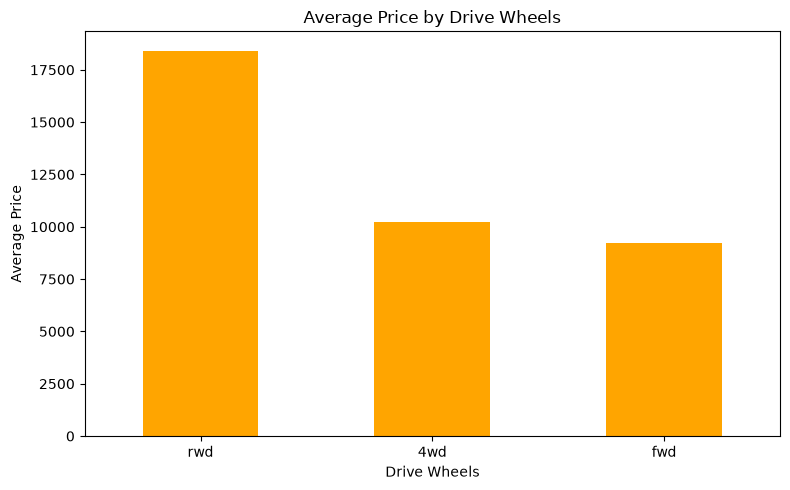

In [32]:
# Average price by body style
avg_price_by_style = df.groupby('body-style')['price'].mean().sort_values(ascending=False)
print('Average price by body-style:')
print(avg_price_by_style)

avg_price_by_style.plot(kind='bar', figsize=(8, 5), color='steelblue')
plt.title('Average Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Average Price')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Average price by drive wheels
avg_price_by_drive = df.groupby('drive-wheels')['price'].mean().sort_values(ascending=False)
print('Average price by drive-wheels:')
print(avg_price_by_drive)

# Show the average price for each drive-wheel group
avg_price_by_drive.plot(kind='bar', figsize=(8, 5), color='orange')
plt.title('Average Price by Drive Wheels')
plt.xlabel('Drive Wheels')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


* For body style;
convertible has highest price, while
hatchback has the lowest price

* For drive wheels
rwd has the highest price, while
fwd has the lowest price


## 4. Effect of independent attributes on price
We use simple statistics and graphs to compare price with continuous variables, categorical variables, and pairs of categorical variables. These comparisons show relationships, but do not prove that a variable causes a price change.


### 4(a). Continuous variables versus price
Correlation values close to 1 show a strong positive relationship. The scatter plots help us see the pattern between each variable and price.


Correlation of continuous variables with price:
curb-weight          0.874
engine-size          0.839
horsepower           0.808
width                0.795
city-L/100km         0.793
length               0.740
highway-mpg         -0.733
city-mpg            -0.714
wheel-base           0.644
bore                 0.556
height               0.176
normalized-losses    0.160
peak-rpm            -0.131
compression-ratio    0.111
stroke               0.106
Name: price, dtype: float64


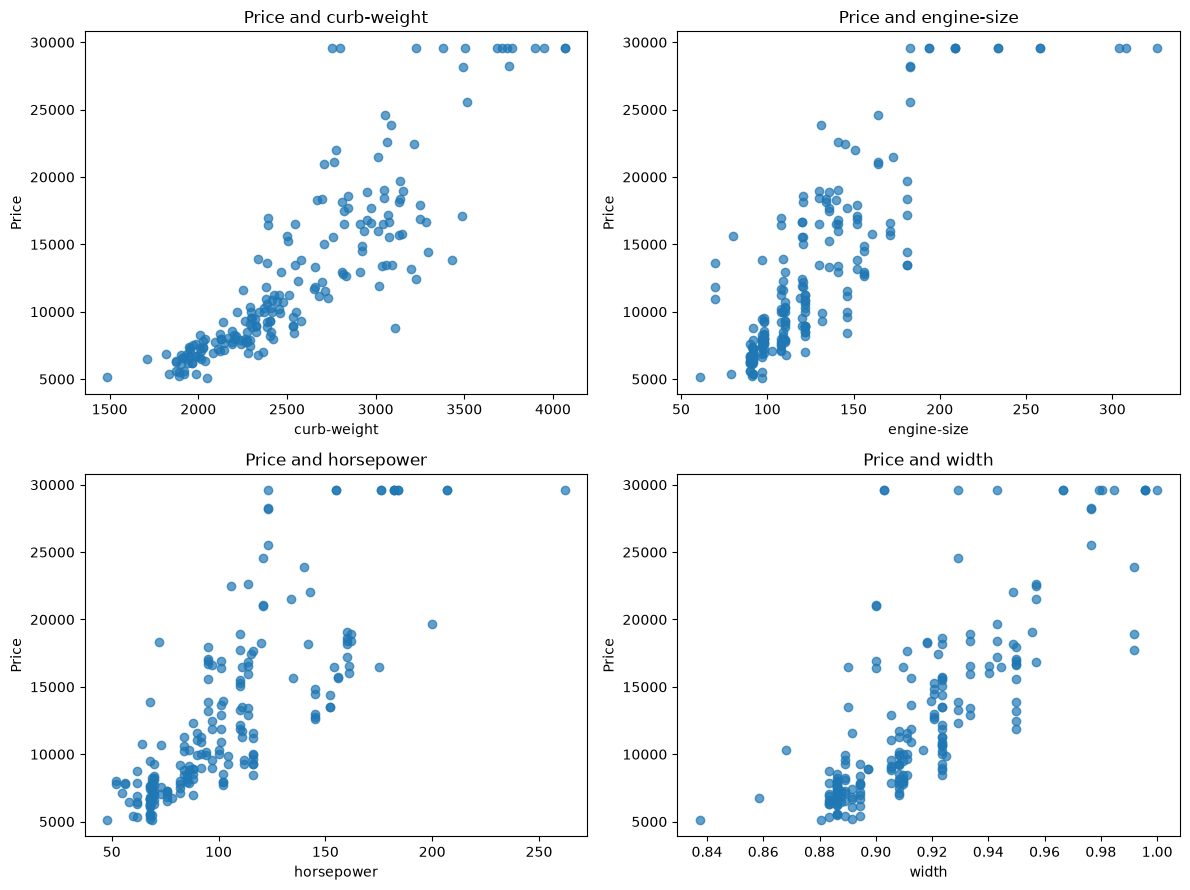

In [33]:
# Correlation shows how strongly two numeric variables change together
continuous_columns = [column for column in df.select_dtypes(include='number').columns
                     if column not in ['price', 'symboling', 'diesel', 'gas']]
price_correlations = df[continuous_columns + ['price']].corr()['price'].drop('price')
price_correlations = price_correlations.reindex(price_correlations.abs().sort_values(ascending=False).index)
print('Correlation of continuous variables with price:')
print(price_correlations.round(3))

# Draw scatter plots for the four variables most related to price
top_variables = price_correlations.head(4).index
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, column in enumerate(top_variables):
    axes[i].scatter(df[column], df['price'], alpha=0.7)
    axes[i].set_title(f'Price and {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Price')

plt.tight_layout()
plt.show()


### 4(b). Categorical variables versus price
For each category, we calculate the average price and number of cars. The bar charts compare average prices between categories.



Average price and number of cars by make:
                   mean  count
make                          
jaguar         29587.50      3
mercedes-benz  28739.19      8
porsche        27064.33      3
bmw            23594.69      8
volvo          18063.18     11
audi           17859.17      6
mercury        16503.00      1
alfa-romero    15498.33      3
peugot         15489.09     11
saab           15223.33      6
mazda          10652.88     17
nissan         10415.67     18
volkswagen     10077.50     12
toyota          9885.81     32
renault         9595.00      2
mitsubishi      9239.77     13
isuzu           8916.50      2
subaru          8541.25     12
honda           8184.69     13
plymouth        7963.43      7
dodge           7875.44      9
chevrolet       6007.00      3

Average price and number of cars by body-style:
                 mean  count
body-style                  
convertible  19739.00      6
hardtop      17841.00      7
sedan        13893.68     94
wagon        12371.

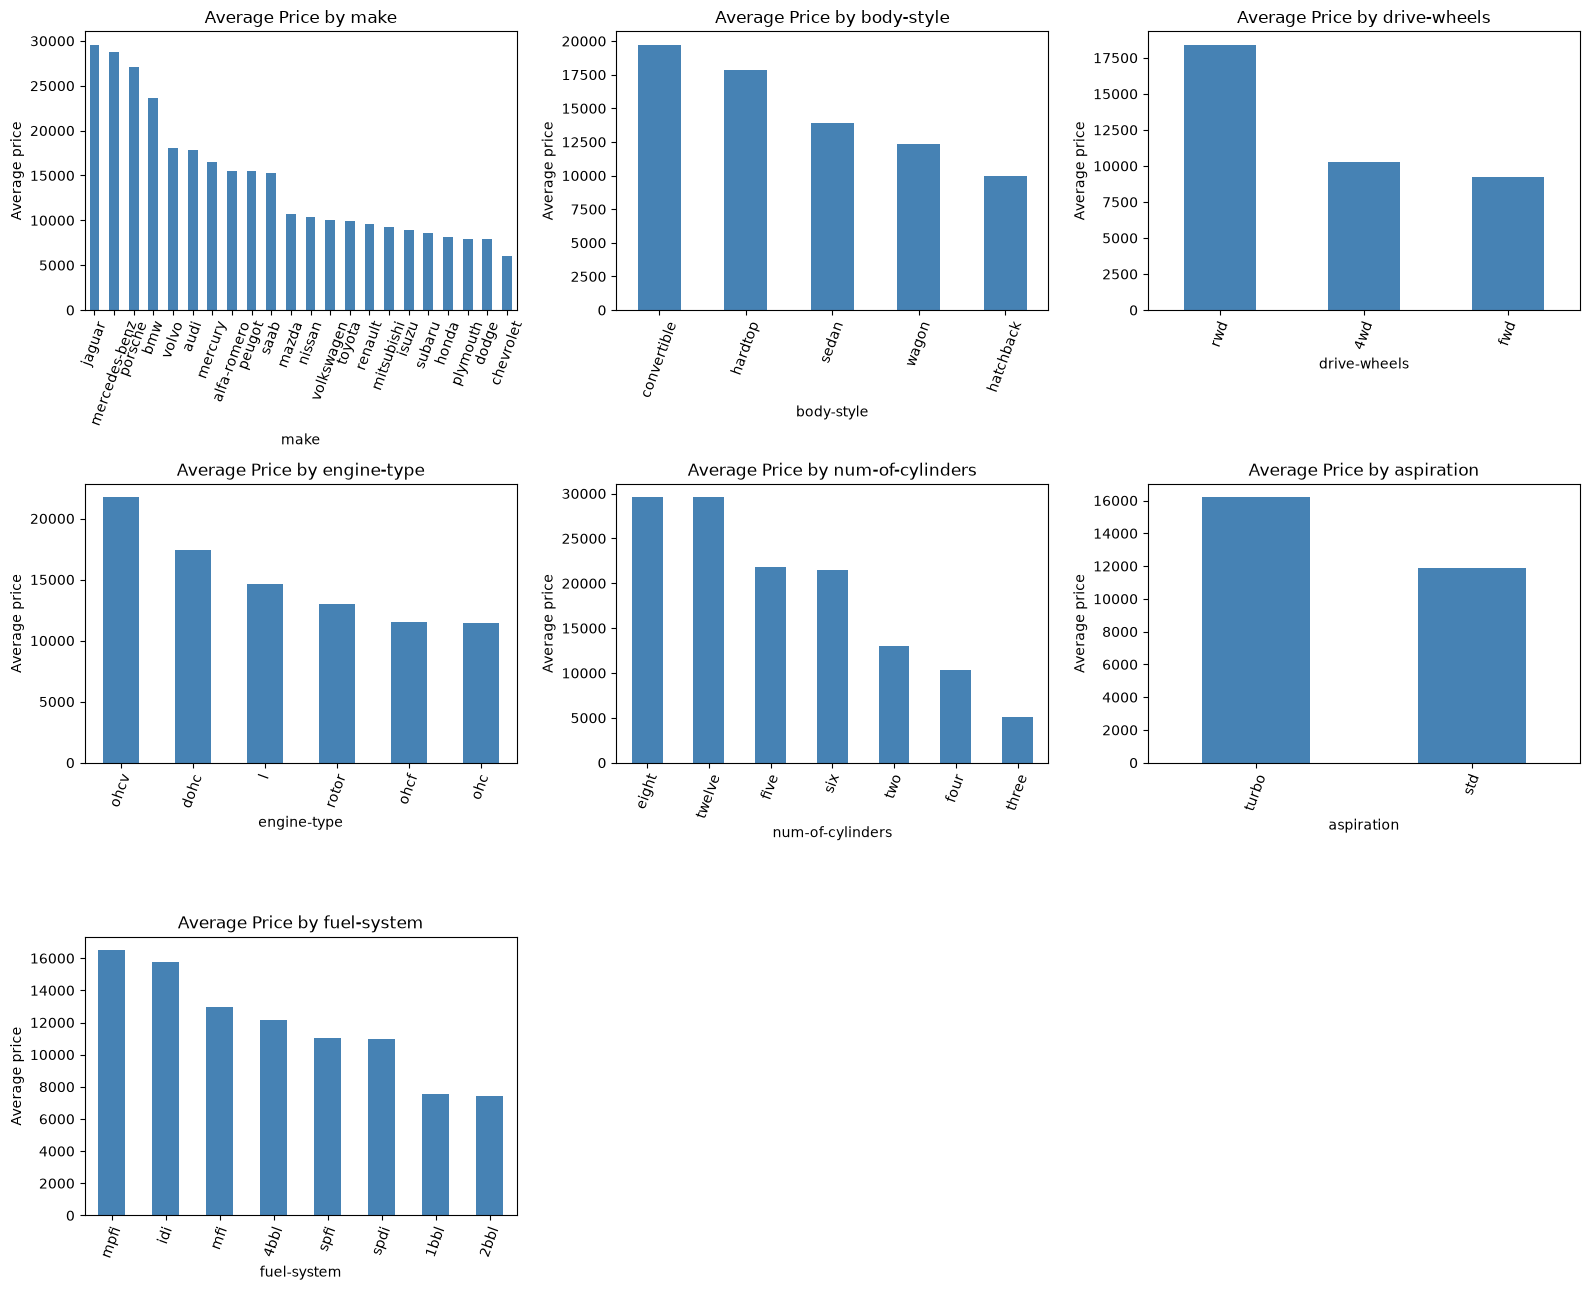

In [34]:
categorical_features = ['make', 'body-style', 'drive-wheels', 'engine-type',
                       'num-of-cylinders', 'aspiration', 'fuel-system']

# Print average price and number of cars in each group
for column in categorical_features:
    price_by_group = df.groupby(column)['price'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    print(f'\nAverage price and number of cars by {column}:')
    print(price_by_group.round(2))

# Draw a bar chart for each categorical feature
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, column in enumerate(categorical_features):
    averages = df.groupby(column)['price'].mean().sort_values(ascending=False)
    averages.plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].set_title(f'Average Price by {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Average price')
    axes[i].tick_params(axis='x', rotation=70)

for i in range(len(categorical_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


### 4(c). Two categorical variables
We compare drive-wheels and body-style together. The table shows the average price for each combination, and the grouped bar chart makes the comparisons easier to see. A blank table cell means that combination is not present in the data.


Average price by drive-wheels and body-style:
body-style    convertible   hardtop  hatchback     sedan     wagon
drive-wheels                                                      
4wd                   NaN       NaN    7603.00  12647.33   9095.75
fwd               11595.0   8249.00    8396.39   9811.80   9997.33
rwd               21367.8  19439.67   14337.78  20233.74  16994.22

Number of cars in each combination:
body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                     0        0          1      3      4
fwd                     1        1         49     55     12
rwd                     5        6         18     36      9


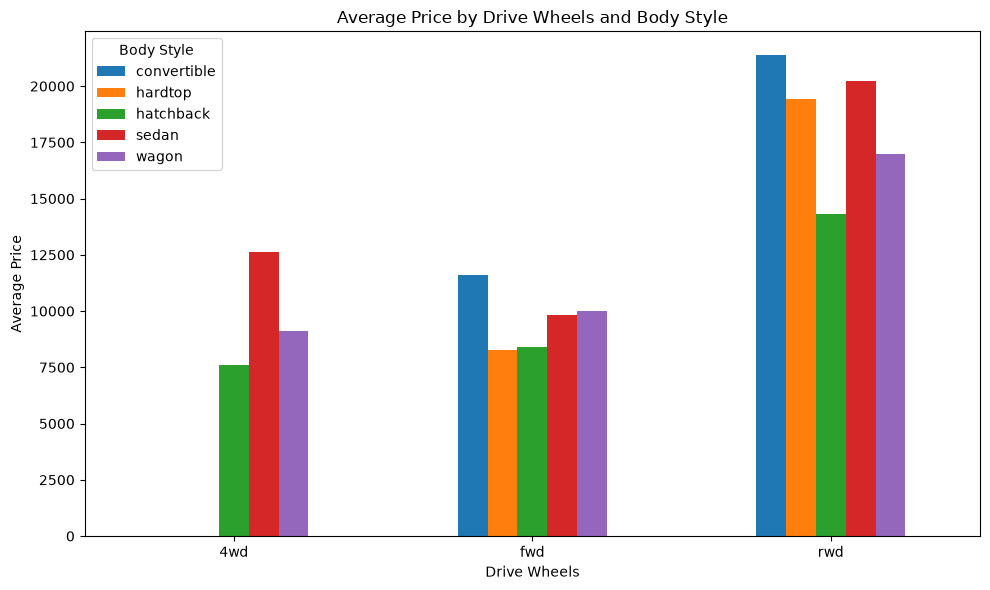

In [35]:
# Average price for each drive-wheels and body-style combination
price_by_two_groups = df.pivot_table(
    values='price', index='drive-wheels', columns='body-style', aggfunc='mean'
)
print('Average price by drive-wheels and body-style:')
print(price_by_two_groups.round(2))

# Show how many cars are in each combination
group_counts = df.pivot_table(
    values='price', index='drive-wheels', columns='body-style', aggfunc='count', fill_value=0
)
print('\nNumber of cars in each combination:')
print(group_counts)

price_by_two_groups.plot(kind='bar', figsize=(10, 6))
plt.title('Average Price by Drive Wheels and Body Style')
plt.xlabel('Drive Wheels')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.legend(title='Body Style')
plt.tight_layout()
plt.show()


### Question 4 findings
Curb weight has the strongest positive correlation with price (about 0.874), followed by engine size (0.839) and horsepower (0.808). This means heavier and more powerful cars tend to cost more.

Average prices also differ between categories. In this cleaned dataset, Jaguar has the highest average price among makes, while hatchbacks have the lowest average price among body styles. Rear-wheel-drive cars have a higher average price than front-wheel-drive cars. Some category groups contain only a few cars, so their averages should be interpreted carefully.

When drive-wheels and body-style are considered together, rear-wheel-drive convertibles have a higher average price than most other combinations. These results describe patterns in this dataset and do not prove that any one feature causes a change in price.


## 5. Main findings and recommendation

### Findings
The main variables that influence price are the ones that show the strongest relationship with price in the analysis.

From this notebook we can see that:
- make has a strong effect on price
- curb weight is strongly related to price
- horsepower and engine size also matter
- body-style and drive-wheels affect the average price

### Recommendation
A car dealer should set prices using a combination of brand, size, power, and vehicle style. Luxury brands, heavier cars, and more powerful cars usually have higher prices.
